# Week 10: Info viz in Python
### Haley Horton
#### Nov. 9th


## James Joyce
I chose a stream of conciousness book, because two of my favorite books are *Dubliners by James Joyce* and *As I Lay Dying by Faulkner*. I chose James Joyce's *Ulysses*, because it has a lot of often repeated letters, words and phrases. I also chose it because I'm stuck 4 sections in and haven't had the wherewithall to finish it.  I changed the background, colors and search criteria slightly.The main charecter's name is Leopold Bloom - so that one makes sense. I could have added it as a stop word, but I thought it was kind of interesting to see how many times it was repeated. I also added more words to dispalay in the word cloud. 

In [11]:
import json                                  # to read the GeoJSON shape files
import re                                    # regular expressions, from Part 9, to pick out the words

import matplotlib.pyplot as plt              # to display the word clouds
import pandas as pd                          # tables of data
import plotly.express as px                  # the quick way to make interactive charts and maps ("px")
import pydeck as pdk                        
from IPython.display import HTML, IFrame     
from wordcloud import STOPWORDS, WordCloud   

In [12]:
with open("joyce.txt", "r", encoding="utf-8") as file:
    book = file.read()
    start = book.index("*** START OF")
end = book.index("*** END OF")
start = book.index("\n", start)
text = book[start:end]

print(len(book), "characters in the file,", len(text), "in the actual text")


1538959 characters in the file, 1519714 in the actual text


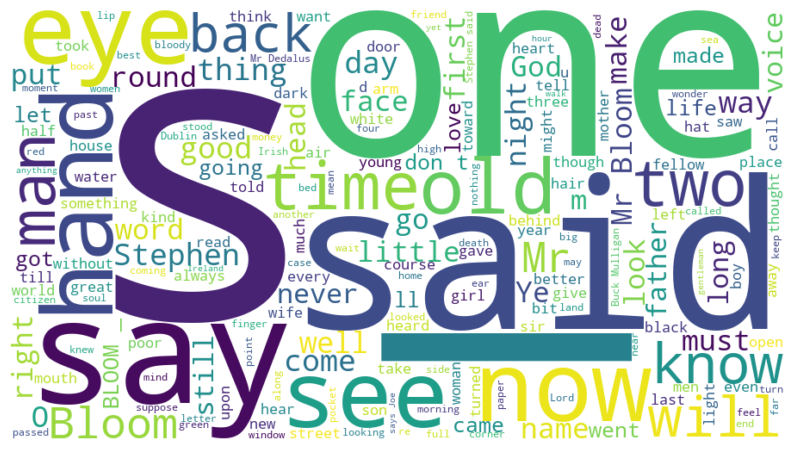

In [13]:
cloud = WordCloud(width=900, height=500, background_color="white", random_state=1).generate(text)

plt.figure(figsize=(10, 6))                  # the size of the plot, in inches
plt.imshow(cloud, interpolation="bilinear")  # draw the cloud's image (bilinear smooths it)
plt.axis("off")                              # hide the plot's axes
plt.show()

In [9]:
my_stopwords = STOPWORDS | {
     "said", "I", "one", "five", "six", "upon", "will", "may", "even", "every", "many", "made", "make",
    "much", "must", "way", "now", "say", "see", "seen", "come", "came", "day", "year", "years",
    "chapter", "illustration",           #
}

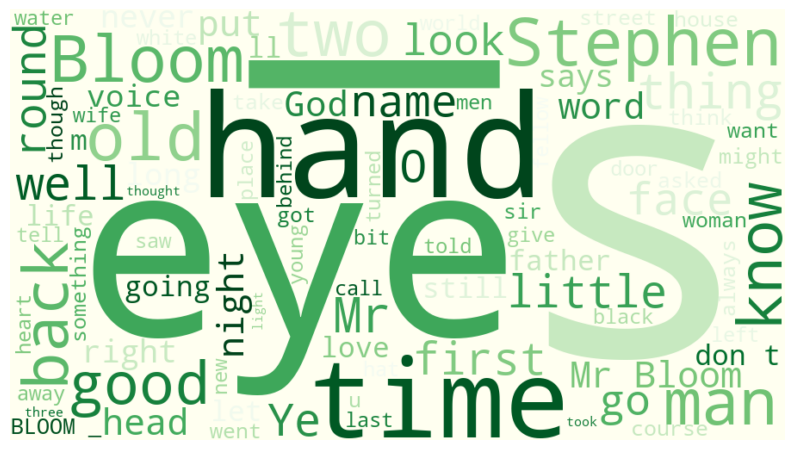

In [10]:
cloud = WordCloud(
    width=900,
    height=500,
    background_color="ivory",
    stopwords=my_stopwords,      # the words to leave out
    colormap="Greens",          # the color palette: try "plasma", "Set2", "Blues"
    max_words=90,                # only draw the 80 most common words
    random_state=2,
).generate(text)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

[('bloom', 1000), ('mr', 719), ('t', 683), ('o', 601), ('stephen', 571), ('old', 490), ('says', 473), ('man', 451), ('two', 391), ('time', 380)]


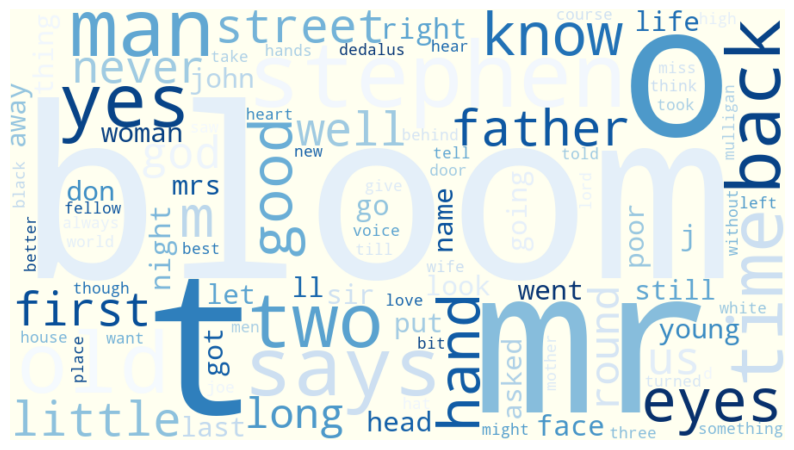

In [8]:
words = re.findall(r"[a-z']+", text.lower())
counts = pd.Series(words).value_counts()
counts = counts[~counts.index.isin(my_stopwords)]
word_counts = counts.head(100).to_dict()
print(list(word_counts.items())[:10])
cloud = WordCloud(width=900, height=500, background_color="ivory", colormap="Blues", random_state=1)
cloud = cloud.generate_from_frequencies(word_counts)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()